# NewsBot 2.0 — Advanced Evaluation & Integration (Final Project)

**Companion notebook** to `NewsBot2_Quickstart.ipynb`. This notebook can run **independently** in Colab: it clones the final GitHub repository, installs dependencies, loads the BBC data, and fits topic models. It does not need variables shared from another notebook. No synthetic publication dates or invented evaluation scores are used. Results are written to `evaluation/` and `results/figures/`.

**Before running:** upload your human-annotated evaluation CSVs and authentic dated/bilingual news CSVs into `data/evaluation/` and `data/multilingual/`. Blank templates are included in the companion ZIP. Missing evidence is explicitly reported as *not evaluated*.

## 1 — Clone project, install dependencies, load dataset and fit topic models

In [1]:
from pathlib import Path
import os, sys, subprocess
REPO='https://github.com/iamhuongthn/ITAI2373-NewsBot-Final.git'
PROJECT_DIR=Path('/content/ITAI2373-NewsBot-Final')
if 'google.colab' in sys.modules:
    if not (PROJECT_DIR/'requirements.txt').exists():
        subprocess.run(['git','clone',REPO,str(PROJECT_DIR)],check=True)
    os.chdir(PROJECT_DIR)
else:
    assert Path('requirements.txt').exists(), 'Run locally from repository root.'
subprocess.run([sys.executable,'-m','pip','install','-r','requirements.txt'],check=True)
subprocess.run([sys.executable,'-m','spacy','download','en_core_web_sm'],check=True)
subprocess.run([sys.executable,'scripts/setup_data.py'],check=True)
from config.settings import DATASET,MODEL
from src.data_processing.data_validator import load_bbc
from src.engine import NewsBotEngine
from src.analysis.topic_modeler import TopicModeler
import pandas as pd,numpy as np,json,re
from collections import Counter
import matplotlib.pyplot as plt
OUT=Path('evaluation');FIG=Path('results/figures');OUT.mkdir(parents=True,exist_ok=True);FIG.mkdir(parents=True,exist_ok=True)
news=load_bbc(DATASET)
engine=NewsBotEngine(DATASET,MODEL)
topic_models={}
for method in ('lda','nmf'):
    tm=TopicModeler(n_topics=7,method=method,random_state=42)
    tm.fit_transform(news.text.tolist())
    topic_models[method]=tm
print('Ready:',len(news),'BBC articles; fitted topic models:',list(topic_models))
print('Optional evaluation CSVs must be placed in data/evaluation/ and data/multilingual/ before executing later cells.')

Ready: 1440 BBC articles; fitted topic models: ['lda', 'nmf']
Optional evaluation CSVs must be placed in data/evaluation/ and data/multilingual/ before executing later cells.


## 2 — LDA/NMF evaluation: topic diversity and NPMI coherence

Topic diversity = unique top terms / all top terms. NPMI uses article-level word co-occurrence; values are descriptive, and coherence estimates depend on preprocessing and corpus. This is **not** a classifier accuracy measure.

,model,n_topics,top_n,topic_diversity,mean_npmi_coherence,topics_with_coherence
0,LDA,7,10,0.771429,0.184349,7
1,NMF,7,10,0.957143,0.314726,7


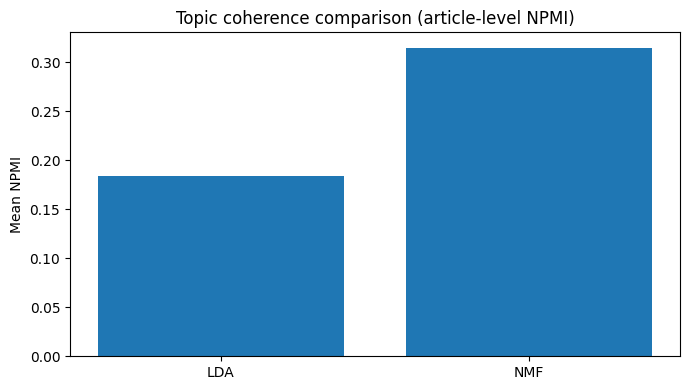

In [2]:
from sklearn.feature_extraction.text import CountVectorizer
texts = news['text'].fillna('').astype(str).tolist()
vectorizer=CountVectorizer(lowercase=True,stop_words='english',binary=True,min_df=2,max_features=20000,token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b')
X=vectorizer.fit_transform(texts).tocsr(); vocabulary=vectorizer.vocabulary_; N=X.shape[0]
df=np.asarray(X.sum(axis=0)).ravel()

def topic_npmi(words):
    indices=[vocabulary[w.lower()] for w in words if w.lower() in vocabulary]
    scores=[]
    for i,a in enumerate(indices):
        for c in indices[i+1:]:
            both=int(X[:,a].multiply(X[:,c]).sum())
            if both==0: continue
            pxy=both/N; pa=df[a]/N; pb=df[c]/N
            scores.append(np.log(pxy/(pa*pb))/-np.log(pxy) if pxy<1 else 1.0)
    return float(np.mean(scores)) if scores else np.nan

rows=[]
for method,tm in topic_models.items():
    topics=[[str(w).lower() for w in tm.get_topic_words(i,10)] for i in range(tm.n_topics)]
    coherence=[topic_npmi(words) for words in topics]
    rows.append({'model':method.upper(),'n_topics':len(topics),'top_n':10,
                 'topic_diversity':len(set(sum(topics,[])))/(len(topics)*10),
                 'mean_npmi_coherence':float(np.nanmean(coherence)) if np.any(np.isfinite(coherence)) else np.nan,
                 'topics_with_coherence':int(np.sum(np.isfinite(coherence)))})
    pd.DataFrame({'topic_id':list(range(len(topics))),'npmi_coherence':coherence,'keywords':[', '.join(t) for t in topics]}).to_csv(OUT/f'{method}_topic_coherence.csv',index=False)
comparison=pd.DataFrame(rows);comparison.to_csv(OUT/'topic_model_comparison.csv',index=False)
display(comparison)
fig,ax=plt.subplots(figsize=(7,4));ax.bar(comparison['model'],comparison['mean_npmi_coherence']);ax.set_title('Topic coherence comparison (article-level NPMI)');ax.set_ylabel('Mean NPMI');fig.tight_layout();fig.savefig(FIG/'topic_coherence_comparison.png',dpi=180);plt.show()

## 3 — Static LDA/NMF charts without Chrome/Kaleido

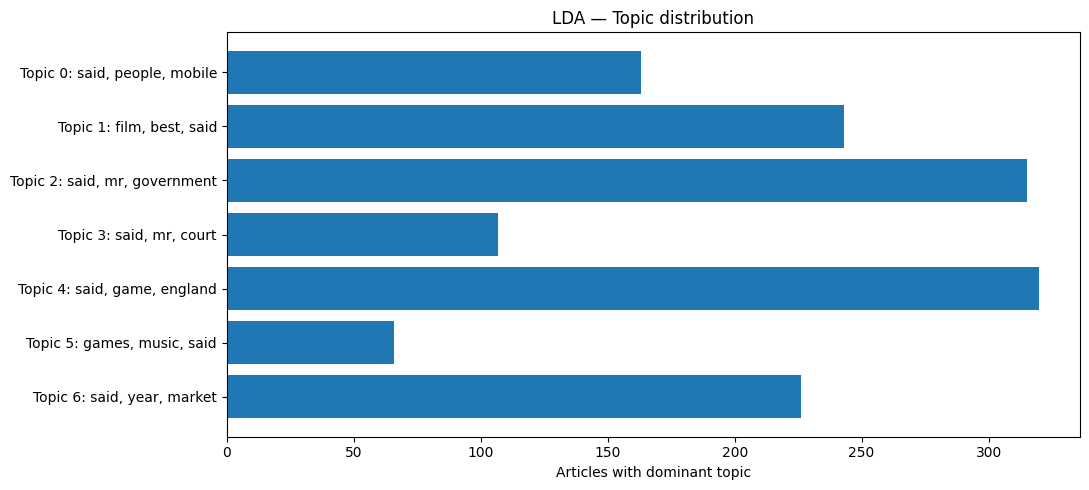

Saved results/figures/lda_topic_keywords.png


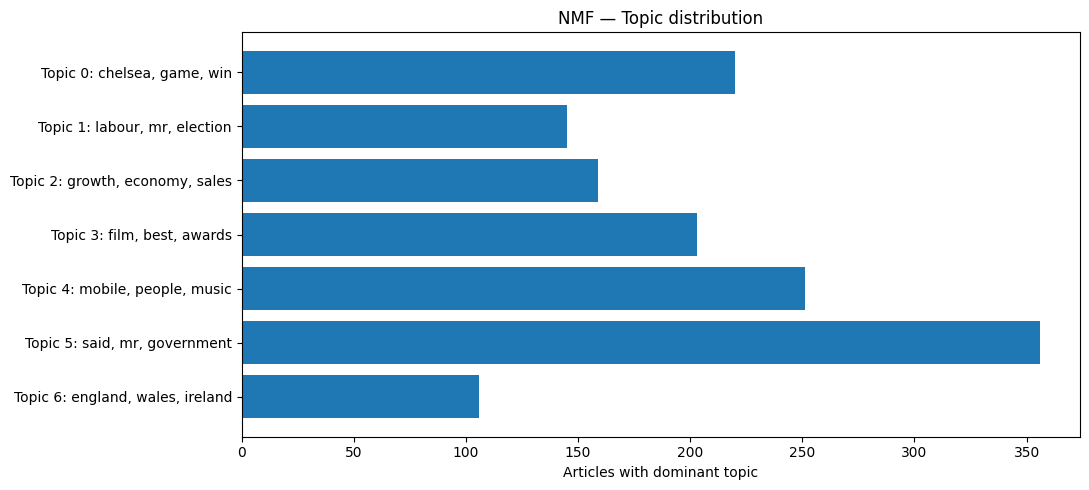

Saved results/figures/nmf_topic_keywords.png


In [3]:
for method,tm in topic_models.items():
    counts=np.bincount(tm.topic_weights.argmax(axis=1),minlength=tm.n_topics)
    labels=[f"Topic {i}: "+', '.join(tm.get_topic_words(i,3)) for i in range(tm.n_topics)]
    fig,ax=plt.subplots(figsize=(11,5))
    ax.barh(labels[::-1],counts[::-1]);ax.set_xlabel('Articles with dominant topic');ax.set_title(method.upper()+' — Topic distribution')
    fig.tight_layout();fig.savefig(FIG/f'{method}_topic_keywords.png',dpi=180,bbox_inches='tight');plt.show()
    print('Saved',FIG/f'{method}_topic_keywords.png')

## 4 — Topic and sentiment evolution using real publication dates

Supply `data/evaluation/dated_news.csv` with `article_id,published_at,language,source,text`. The notebook refuses to fabricate dates. Minimum 10 dated records for a meaningful demo; larger balanced samples are recommended.

In [4]:
dated_path=Path('data/evaluation/dated_news.csv')
if not dated_path.exists():
    print('NOT EVALUATED: provide',dated_path,'with real publication timestamps.')
else:
    dated=pd.read_csv(dated_path)
    required={'article_id','published_at','language','source','text'}
    assert required <= set(dated),f'Missing columns: {required-set(dated)}'
    dated['published_at']=pd.to_datetime(dated['published_at'],utc=True,errors='coerce')
    dated=dated.dropna(subset=['published_at','text']).copy()
    dated=dated[dated['text'].astype(str).str.len()>30].copy()
    assert len(dated)>=10,'At least 10 genuine dated articles needed.'
    dated['month']=dated['published_at'].dt.to_period('M').astype(str)
    dated['sentiment_compound']=dated['text'].apply(lambda s: engine.sentiment(str(s))['scores']['compound'])
    # Topic assignment using the existing fitted vectorizer/model, not a fresh model
    tm=topic_models['nmf']; vec=getattr(tm,'vectorizer',None); model=getattr(tm,'model',None)
    if vec is not None and model is not None:
        dated['topic_id']=model.transform(vec.transform(dated['text'].astype(str))).argmax(axis=1)
        counts=dated.groupby(['month','topic_id']).size().unstack(fill_value=0)
        counts.to_csv(OUT/'topic_evolution.csv')
        ax=counts.plot(figsize=(10,5),marker='o',title='Topic evolution — authentic dated articles');ax.set_ylabel('Article count');ax.figure.tight_layout();ax.figure.savefig(FIG/'topic_evolution.png',dpi=180);plt.show()
    else:
        print('Topic evolution skipped: fitted TopicModeler vectorizer/model attributes not available; inspect topic_modeler.py.')
    sentiment=dated.groupby('month')['sentiment_compound'].agg(['mean','count']);sentiment.to_csv(OUT/'sentiment_evolution.csv')
    ax=sentiment['mean'].plot(figsize=(10,4),marker='o',title='Mean VADER sentiment by month');ax.set_ylabel('Mean compound');ax.figure.tight_layout();ax.figure.savefig(FIG/'sentiment_evolution.png',dpi=180);plt.show()

NOT EVALUATED: provide data/evaluation/dated_news.csv with real publication timestamps.


## 5 — Cross-language original-source comparison

Supply `data/multilingual/bilingual_news.csv` with `event_id,language,source,url,published_at,text`. Use independently written English (`en`) and Vietnamese (`vi`) articles about the same event. **Do not use translations of one article as independent reporting.**

In [5]:
bilingual_path=Path('data/multilingual/bilingual_news.csv')
if not bilingual_path.exists():
    print('NOT EVALUATED: provide independently authored bilingual news articles:',bilingual_path)
else:
    bilingual=pd.read_csv(bilingual_path)
    cols={'event_id','language','source','url','published_at','text'}
    assert cols <= set(bilingual),f'Missing: {cols-set(bilingual)}'
    bilingual=bilingual.dropna(subset=['event_id','language','text'])
    bilingual=bilingual[bilingual.language.isin(['en','vi'])].copy()
    bilingual['detected_language']=bilingual.text.apply(lambda s:engine.language.detect(str(s)))
    bilingual['language_correct']=bilingual.detected_language==bilingual.language
    print('Language detection accuracy on supplied sample:',round(bilingual.language_correct.mean(),3))
    bilingual['english_text']=[str(t) if l=='en' else engine.translate(str(t),source='vi',target='en') for t,l in zip(bilingual.text,bilingual.language)]
    bilingual['sentiment_en']=bilingual.english_text.apply(lambda s:engine.sentiment(s)['scores']['compound'])
    bilingual.to_csv(OUT/'cross_language_article_results.csv',index=False)
    grouped=bilingual.groupby(['event_id','language']).agg(n_articles=('text','size'),mean_sentiment=('sentiment_en','mean')).reset_index()
    grouped.to_csv(OUT/'cross_language_event_comparison.csv',index=False)
    display(grouped)
    print('Note: translated sentiment is exploratory; do not interpret differences as proven cultural bias.')

NOT EVALUATED: provide independently authored bilingual news articles: data/multilingual/bilingual_news.csv


## 6 — Semantic retrieval: human-labeled Precision@K / Recall@K

Supply `data/evaluation/search_relevance.csv` with `query,relevant_article_indices`. Each `relevant_article_indices` field is a pipe-separated list of relevant BBC row indices, established by human judgment. Unlabeled queries are not scored.

In [6]:
rel_path=Path('data/evaluation/search_relevance.csv')
if not rel_path.exists():
    print('NOT EVALUATED: human relevance labels required:',rel_path)
else:
    labels=pd.read_csv(rel_path).dropna(subset=['query','relevant_article_indices'])
    rows=[]
    for _,r in labels.iterrows():
        relevant={int(x.strip()) for x in str(r.relevant_article_indices).split('|') if x.strip()}
        if not relevant: continue
        found=[int(x['index']) for x in engine.search(str(r['query']),top_k=5)]
        hits=len(set(found)&relevant)
        rows.append({'query':r['query'],'precision_at_5':hits/5,'recall_at_5':hits/len(relevant),'hits':hits,'relevant_total':len(relevant)})
    scores=pd.DataFrame(rows)
    assert len(scores)>0,'No labeled queries to evaluate.'
    scores.to_csv(OUT/'semantic_search_metrics.csv',index=False)
    display(scores);print('Macro mean:',scores[['precision_at_5','recall_at_5']].mean().to_dict())

NOT EVALUATED: human relevance labels required: data/evaluation/search_relevance.csv


## 7 — Summarization quality: human factuality rubric

Supply `data/evaluation/summary_review.csv` with `article_id,generated_summary,factuality_1to5,coverage_1to5,notes`. Score only manually reviewed summaries. ROUGE requires reference summaries, which the BBC dataset does not provide.

In [7]:
review_path=Path('data/evaluation/summary_review.csv')
if not review_path.exists():
    print('NOT EVALUATED: human summary review required:',review_path)
else:
    reviews=pd.read_csv(review_path)
    required={'article_id','generated_summary','factuality_1to5','coverage_1to5','notes'}
    assert required <= set(reviews),f'Missing: {required-set(reviews)}'
    for col in ['factuality_1to5','coverage_1to5']:
        reviews[col]=pd.to_numeric(reviews[col],errors='coerce')
        assert reviews[col].dropna().between(1,5).all(),f'{col} must be 1–5'
    reviewed=reviews.dropna(subset=['factuality_1to5','coverage_1to5'])
    assert len(reviewed)>0,'No manually scored summaries.'
    summary=reviewed[['factuality_1to5','coverage_1to5']].agg(['mean','count'])
    summary.to_csv(OUT/'summarization_quality_metrics.csv');display(summary)

NOT EVALUATED: human summary review required: data/evaluation/summary_review.csv


## 8 — Conversation integration checks (no hidden assumptions)

In [8]:
from src.conversation.interface import ConversationalInterface
cbot=ConversationalInterface(engine)
qs=['Find technology news about software','What is the sentiment of the first article?','Summarize that article','What organizations are mentioned in it?']
trace=[]
for q in qs:
    resp=cbot.ask(q)
    trace.append({'query':q,'intent':resp.get('intent'),'selected_article_id':cbot.selected_index,'response':resp})
ids=[x['selected_article_id'] for x in trace]
assert ids[0] is not None and len(set(ids))==1,'Conversation did not retain article context'
assert [x['intent'] for x in trace]==['search','sentiment','summarize','entities'],'Unexpected intent sequence'
entity_resp=trace[-1]['response'].get('entities',[])
org_only=[e for e in entity_resp if e.get('label')=='ORG']
print('Conversation context and intents: PASS; article',ids[0]);print('ORG-only entities:',org_only)
if len(org_only)!=len(entity_resp): print('GAP: organization-specific query returned non-ORG entity labels; filter in interface implementation.')
(OUT/'advanced_conversation_trace.json').write_text(json.dumps(trace,indent=2,ensure_ascii=False,default=str),encoding='utf-8')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (11 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cpu


Conversation context and intents: PASS; article 1347
ORG-only entities: [{'text': '3ami', 'label': 'ORG', 'start': 1471, 'end': 1475}]
GAP: organization-specific query returned non-ORG entity labels; filter in interface implementation.


5023

## 9 — Run tests and export advanced evidence ZIP

In [9]:
import subprocess,sys,zipfile
r=subprocess.run([sys.executable,'-m','pytest','-q'],capture_output=True,text=True)
(OUT/'advanced_pytest_results.txt').write_text(r.stdout+'\n'+r.stderr,encoding='utf-8')
print(r.stdout);assert r.returncode==0,'pytest failed'
zip_path=Path('/content/NewsBot2_Advanced_Results.zip') if Path('/content').exists() else Path('NewsBot2_Advanced_Results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for folder in (OUT,FIG):
        for path in folder.rglob('*'):
            if path.is_file(): z.write(path,arcname=str(path))
print('Saved:',zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError: pass

.................                                                        [100%]
17 passed in 3.36s

Saved: /content/NewsBot2_Advanced_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>